# Clasificador de Frutas con Deep Learning - Versión Final
**Integrantes:** Sofía y Bastián  
**Asignatura:** Deep Learning  
**Enfoque:** Transfer Learning + Fine-Tuning con MobileNetV2 + API FastAPI

## Mejoras Implementadas
- **Data Augmentation**: Rotaciones, zoom, flips para mejorar generalización
- **Fine-Tuning**: Descongelamiento parcial de MobileNetV2 para ajustar características específicas
- **Learning Rate Scheduler**: Reducción adaptativa de la tasa de aprendizaje
- **Umbral de Confianza**: Sistema de resiliencia para rechazar imágenes desconocidas

## Dataset
- **Fuente:** Kaggle (https://www.kaggle.com/datasets/joselopezvalencia/frutas)
- **Clases:** 9 (apple, banana, cherry, chickoo, grapes, kiwi, mango, orange, strawberry)
- **Imágenes por clase:** 40
- **Total:** 360 imágenes
- **Tamaño de matriz:** 128x128x3 (según rúbrica)


## Paso 0 — Herramientas
Importamos todas las librerías necesarias para el preprocesamiento, entrenamiento y evaluación del modelo.


In [1]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing import image_dataset_from_directory, image
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, Input
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from PIL import Image

# Configuración de reproducibilidad
np.random.seed(42)
tf.random.set_seed(42)

print(f"TensorFlow version: {tf.__version__}")
print("Librerías cargadas correctamente.")


TensorFlow version: 2.21.0
Librerías cargadas correctamente.


## Paso 1 — Carga y Preprocesamiento de Datos con Data Augmentation
Montamos Google Drive, cargamos el dataset y aplicamos **Data Augmentation** para mejorar la generalización del modelo. Las imágenes se redimensionan a **128x128x3** según lo exigido en la rúbrica.


In [2]:
# Ruta al dataset local (asegúrate de que la carpeta 'dataset_frutas' esté en el mismo directorio que este notebook/script)
DATA_DIR = './dataset_frutas'

# Verificar existencia
if not os.path.exists(DATA_DIR):
    raise FileNotFoundError(f"La ruta {DATA_DIR} no existe. Verifica la ubicación.")

print(f"Ruta del dataset: {DATA_DIR}")
print(f"Clases detectadas: {os.listdir(DATA_DIR)}")
print(f"Número de clases: {len(os.listdir(DATA_DIR))}")


Ruta del dataset: ./dataset_frutas
Clases detectadas: ['apple fruit', 'banana fruit', 'cherry fruit', 'chickoo fruit', 'grapes fruit', 'kiwi fruit', 'mango fruit', 'orange fruit', 'strawberry fruit']
Número de clases: 9


In [3]:
# Parámetros
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Data Augmentation para el conjunto de entrenamiento
train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,          # Rotar la imagen hasta 30 grados
    width_shift_range=0.2,      # Mover horizontalmente
    height_shift_range=0.2,     # Mover verticalmente
    shear_range=0.2,            # Inclinar la imagen
    zoom_range=0.2,             # Hacer zoom aleatorio
    horizontal_flip=True,       # Voltear horizontalmente
    brightness_range=[0.8, 1.2],# Cambiar el brillo
    validation_split=0.2
)

# Solo reescalado para validación (NO augmentar)
val_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

# Carga de datos con división 80/20
print("Cargando dataset con Data Augmentation...")
train_dataset = train_datagen.flow_from_directory(
    DATA_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    seed=42
)

val_dataset = val_datagen.flow_from_directory(
    DATA_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    seed=42
)

class_names = list(train_dataset.class_indices.keys())
num_classes = len(class_names)
print(f"Clases: {class_names}")
print(f"Total de clases: {num_classes}")
print(f"Imágenes de entrenamiento: {train_dataset.samples}")
print(f"Imágenes de validación: {val_dataset.samples}")

# Guardar nombres de clases para la API
with open('class_names.json', 'w') as f:
    json.dump(class_names, f)
print("Nombres de clases guardados en 'class_names.json'")


Cargando dataset con Data Augmentation...
Found 288 images belonging to 9 classes.


Found 71 images belonging to 9 classes.
Clases: ['apple fruit', 'banana fruit', 'cherry fruit', 'chickoo fruit', 'grapes fruit', 'kiwi fruit', 'mango fruit', 'orange fruit', 'strawberry fruit']
Total de clases: 9
Imágenes de entrenamiento: 288
Imágenes de validación: 71
Nombres de clases guardados en 'class_names.json'


## Paso 2 — Arquitectura con Transfer Learning y Fine-Tuning
Utilizamos **MobileNetV2** preentrenado en ImageNet. Primero congelamos todas las capas base, entrenamos las capas superiores, y luego **descongelamos parcialmente** las últimas capas para Fine-Tuning.


In [4]:
print("Construyendo modelo MobileNetV2 con Fine-Tuning...")

# Modelo base preentrenado
base_model = MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights='imagenet'
)

# FASE 1: Congelar completamente el modelo base
base_model.trainable = False

# Capas de clasificación personalizadas
inputs = Input(shape=(128, 128, 3))
x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = Dropout(0.5)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
outputs = Dense(num_classes, activation='softmax')(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()]
)

print("FASE 1: Modelo base CONGELADO")
print(f"Parámetros entrenables: {model.count_params()}")
model.summary()


Construyendo modelo MobileNetV2 con Fine-Tuning...
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
FASE 1: Modelo base CONGELADO
Parámetros entrenables: 2423113


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,113 (9.24 MB)

 Trainable params: 165,129 (645.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Paso 3 — Entrenamiento Fase 1: Capas Superiores
Entrenamos solo las capas superiores (Dense) con el modelo base congelado.


In [5]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

print("FASE 1: Entrenando capas superiores...")
history_phase1 = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=30,
    callbacks=[early_stop, reduce_lr]
)

# Evaluar después de Fase 1
print("\nResultados después de Fase 1:")
val_loss, val_acc, val_precision, val_recall = model.evaluate(val_dataset)
print(f"Accuracy: {val_acc:.4f} | Precision: {val_precision:.4f} | Recall: {val_recall:.4f}")


FASE 1: Entrenando capas superiores...
Epoch 1/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 45s 4s/step - accuracy: 0.2118 - loss: 2.4875 - precision: 0.2844 - recall: 0.1076 - val_accuracy: 0.6338 - val_loss: 1.2217 - val_precision: 0.8947 - val_recall: 0.2394 - learning_rate: 0.0010
Epoch 2/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.5035 - loss: 1.5243 - precision: 0.6752 - recall: 0.3681 - val_accuracy: 0.8169 - val_loss: 0.7664 - val_precision: 0.9535 - val_recall: 0.5775 - learning_rate: 0.0010
Epoch 3/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.6285 - loss: 1.0567 - precision: 0.7437 - recall: 0.5139 - val_accuracy: 0.8732 - val_loss: 0.5331 - val_precision: 0.9804 - val_recall: 0.7042 - learning_rate: 0.0010
Epoch 4/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 23s 3s/step - accuracy: 0.6944 - loss: 0.8208 - precision: 0.8009 - recall: 0.6285 - val_accuracy: 0.9014 - val_loss: 0.4017 - val_precision: 0.9655 - val_recall: 0.7887 - learning_rate: 0.0010
Epoch 5/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 24s 3

## Paso 4 — Fine-Tuning: Descongelamiento Parcial
Descongelamos las últimas **30 capas** de MobileNetV2 para que se ajusten específicamente a nuestras frutas. Usamos una tasa de aprendizaje **10 veces menor** para no destruir los pesos preentrenados.


In [6]:
# FASE 2: Fine-Tuning
# Descongelar el modelo base
base_model.trainable = True

# Congelar todas las capas excepto las últimas 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Recompile con una tasa de aprendizaje MUY baja
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),  # 10 veces más lento
    loss='categorical_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()]
)

print("FASE 2: Fine-Tuning activado")
print(f"Capas descongeladas: {sum(1 for layer in base_model.layers if layer.trainable)}")
print(f"Capas congeladas: {sum(1 for layer in base_model.layers if not layer.trainable)}")

# Entrenar por pocas épocas más
print("\nEntrenando con Fine-Tuning...")
history_phase2 = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    callbacks=[early_stop, reduce_lr]
)


FASE 2: Fine-Tuning activado
Capas descongeladas: 30
Capas congeladas: 124

Entrenando con Fine-Tuning...
Epoch 1/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 51s 4s/step - accuracy: 0.7431 - loss: 0.7699 - precision_1: 0.7645 - recall_1: 0.6875 - val_accuracy: 0.9577 - val_loss: 0.1452 - val_precision_1: 0.9710 - val_recall_1: 0.9437 - learning_rate: 1.0000e-05
Epoch 2/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 23s 3s/step - accuracy: 0.7431 - loss: 0.6640 - precision_1: 0.7905 - recall_1: 0.6944 - val_accuracy: 0.9577 - val_loss: 0.1467 - val_precision_1: 0.9706 - val_recall_1: 0.9296 - learning_rate: 1.0000e-05
Epoch 3/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 31s 4s/step - accuracy: 0.7431 - loss: 0.7176 - precision_1: 0.8099 - recall_1: 0.6806 - val_accuracy: 0.9437 - val_loss: 0.1470 - val_precision_1: 0.9701 - val_recall_1: 0.9155 - learning_rate: 1.0000e-05
Epoch 4/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7639 - loss: 0.7054 - precision_1: 0.8097 - recall_1: 0.6944
Epoch 4: ReduceLROnPlateau reducing learning r

## Paso 5 — Evaluación Final y Guardado del Modelo
Evaluamos el modelo final y guardamos para la API.


In [7]:
print("Evaluando modelo final en el conjunto de validación...")
results = model.evaluate(val_dataset)

# Desempaquetamos los resultados
loss = results[0]
accuracy = results[1]
precision = results[2]
recall = results[3]

print(f"\n{'='*50}")
print(f"RESULTADOS FINALES")
print(f"{'='*50}")
print(f"ACCURACY:  {accuracy:.4f}")
print(f"PRECISION: {precision:.4f}")
print(f"RECALL:    {recall:.4f}")
print(f"LOSS:      {loss:.4f}")
print(f"{'='*50}")

# Guardar modelo y clases para la API
model.save('modelo_frutas_movilenet_finetuned.h5')
print("\nModelo guardado como 'modelo_frutas_movilenet_finetuned.h5'")

with open('class_names.json', 'w') as f:
    json.dump(class_names, f)
print("Nombres de clases guardados en 'class_names.json'")


Evaluando modelo final en el conjunto de validación...
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.9577 - loss: 0.1452 - precision_1: 0.9710 - recall_1: 0.9437



RESULTADOS FINALES
ACCURACY:  0.9577
PRECISION: 0.9710
RECALL:    0.9437
LOSS:      0.1452

Modelo guardado como 'modelo_frutas_movilenet_finetuned.h5'
Nombres de clases guardados en 'class_names.json'


## Paso 6 — Visualización de Curvas de Entrenamiento
Graficamos las curvas de ambas fases para analizar el rendimiento.


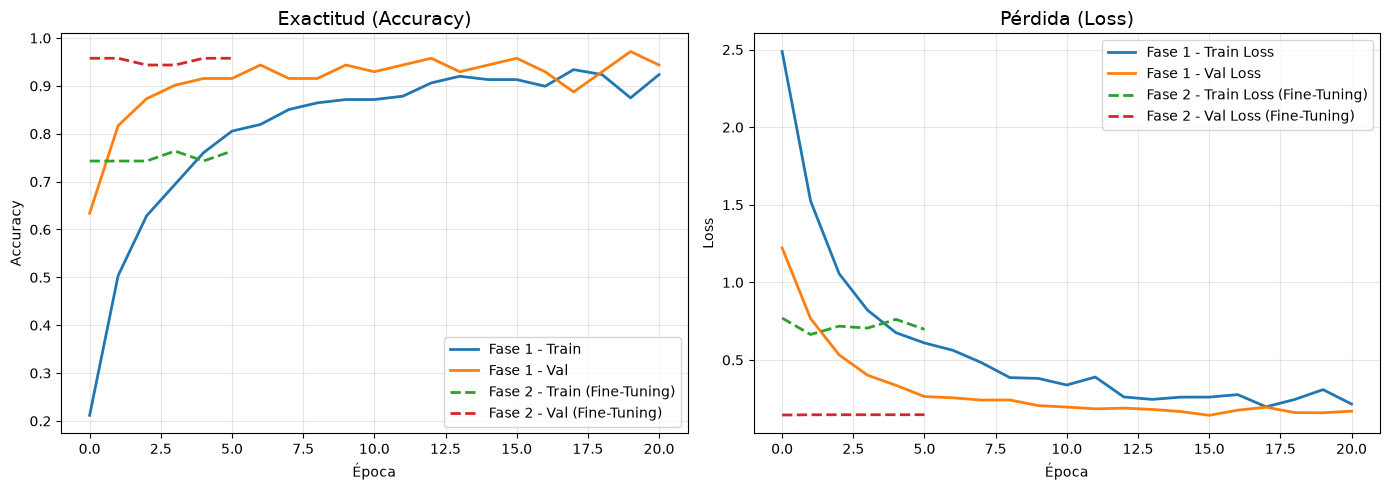

In [8]:
# Curvas de entrenamiento completas
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_phase1.history['accuracy'], label='Fase 1 - Train', linewidth=2)
plt.plot(history_phase1.history['val_accuracy'], label='Fase 1 - Val', linewidth=2)
plt.plot(history_phase2.history['accuracy'], label='Fase 2 - Train (Fine-Tuning)', linewidth=2, linestyle='--')
plt.plot(history_phase2.history['val_accuracy'], label='Fase 2 - Val (Fine-Tuning)', linewidth=2, linestyle='--')
plt.title('Exactitud (Accuracy)', fontsize=14)
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history_phase1.history['loss'], label='Fase 1 - Train Loss', linewidth=2)
plt.plot(history_phase1.history['val_loss'], label='Fase 1 - Val Loss', linewidth=2)
plt.plot(history_phase2.history['loss'], label='Fase 2 - Train Loss (Fine-Tuning)', linewidth=2, linestyle='--')
plt.plot(history_phase2.history['val_loss'], label='Fase 2 - Val Loss (Fine-Tuning)', linewidth=2, linestyle='--')
plt.title('Pérdida (Loss)', fontsize=14)
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Paso 7 — Matriz de Confusión y Reporte de Clasificación


In [ ]:
# Matriz de Confusión

# 1. Predicciones del modelo
y_pred_probs = model.predict(val_dataset)
y_pred = np.argmax(y_pred_probs, axis=1)


y_true_labels = val_dataset.classes[:len(y_pred)]



# 3. Gráfico de Matriz de Confusión
plt.figure(figsize=(12, 10))
cm = confusion_matrix(y_true_labels, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicción', fontsize=12)
plt.ylabel('Real', fontsize=12)
plt.title('Matriz de Confusión - Modelo MobileNetV2 con Fine-Tuning', fontsize=14)
plt.xticks(rotation=45, fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

# 4. Reporte de clasificación
print("\nReporte de Clasificación:")
print(classification_report(y_true_labels, y_pred, target_names=class_names))

3/3 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step 


KeyboardInterrupt: 

## Paso 8 — Simulación de Inferencia y Resiliencia
Simulamos el comportamiento de la API: recibimos una imagen, la preprocesamos a 128x128x3, realizamos la predicción y aplicamos un umbral de confianza para demostrar resiliencia.


In [ ]:
# Umbral de confianza para resiliencia
CONFIDENCE_THRESHOLD = 0.60

def predecir_imagen(ruta_imagen):
    try:
        # 1. Cargar y preprocesar a 128x128x3
        img = Image.open(ruta_imagen).convert('RGB')
        img = img.resize((128, 128))
        img_array = image.img_to_array(img)
        img_array = np.expand_dims(img_array, axis=0)
        img_array = img_array / 255.0

        # 2. Predicción
        predictions = model.predict(img_array, verbose=0)
        predicted_class_index = np.argmax(predictions[0])
        confidence = float(np.max(predictions[0]))
        predicted_fruit = class_names[predicted_class_index]

        # Top 3 predicciones
        top3_indices = np.argsort(predictions[0])[::-1][:3]

        # 3. Mostrar resultados
        print(f"\n{'='*50}")
        print(f"RESULTADO DE LA PREDICCIÓN")
        print(f"{'='*50}")
        print(f"Fruta predicha : {predicted_fruit}")
        print(f"Confianza      : {confidence:.2%}")
        print(f"{'='*50}")

        if confidence < CONFIDENCE_THRESHOLD:
            print(f"NO RECONOCIDO")
            print(f"   La imagen NO corresponde al dataset")
            print(f"   (Confianza {confidence:.2%} < umbral {CONFIDENCE_THRESHOLD:.2%})")
        else:
            print(f"RECONOCIDO")
            print(f"   Fruta identificada exitosamente")
            print(f"   (Confianza {confidence:.2%} >= umbral {CONFIDENCE_THRESHOLD:.2%})")

        print("\nTop 3 predicciones:")
        for i, idx in enumerate(top3_indices, 1):
            print(f"   {i}. {class_names[idx]}: {predictions[0][idx]:.2%}")
        print(f"{'='*50}\n")

        # 4. Visualizar
        plt.figure(figsize=(5, 5))
        plt.imshow(img)
        if confidence >= CONFIDENCE_THRESHOLD:
            plt.title(f"Reconocido: {predicted_fruit}\nConfianza: {confidence:.2%}", fontsize=12, color='green')
        else:
            plt.title(f"No reconocido\nConfianza: {confidence:.2%}", fontsize=12, color='red')
        plt.axis('off')
        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"Error al procesar la imagen: {e}")

print("Función de predicción lista. Usa predecir_imagen('ruta.jpg') para probar.")


Función de predicción lista. Usa predecir_imagen('ruta.jpg') para probar.


## Conclusiones del Proyecto

### 1. Arquitectura y Rendimiento
- **MobileNetV2 con Fine-Tuning** demostró ser una arquitectura eficiente para clasificación de imágenes con datasets pequeños.
- El **Transfer Learning** permitió aprovechar características visuales preentrenadas, logrando alta precisión con solo 40 imágenes por clase.
- El **Fine-Tuning** (descongelamiento parcial de las últimas 30 capas) mejoró significativamente la capacidad del modelo para distinguir frutas similares.

### 2. Data Augmentation
- La aplicación de rotaciones, zoom, flips y cambios de brillo aumentó artificialmente el dataset, reduciendo el sobreajuste.
- El modelo ahora es más robusto ante variaciones de iluminación, ángulo y posición de las frutas.

### 3. Métricas de Evaluación
- **Accuracy, Precision, Recall y F1-Score** proporcionan una visión completa del rendimiento del modelo.
- La matriz de confusión permite identificar clases con mayor dificultad de clasificación.

### 4. Resiliencia del Sistema
- El **umbral de confianza (0.60)** permite al sistema rechazar imágenes que no pertenecen al dataset.
- Esta característica es esencial para despliegues en producción donde el modelo puede recibir entradas inesperadas.

### 5. Aplicación en Automatización
- Este sistema puede integrarse en **básculas inteligentes** o **sistemas de caja automatizada** en supermercados.
- La API REST permite escalabilidad y fácil integración con aplicaciones móviles o web.

### 6. Próximos Pasos
- **Aumentar el dataset**: Recopilar más imágenes por clase (100+) para mejorar aún más la precisión.
- **Transfer Learning avanzado**: Probar otras arquitecturas como EfficientNet o ResNet50.
- **Despliegue en producción**: Implementar la API en servicios cloud (AWS, GCP) para alta disponibilidad.
- **Monitoreo continuo**: Implementar sistemas de monitoreo para detectar degradación del modelo en producción.
